# 04 · Hedonic pricing: what should a flat in each profile cost today?
**Owner:** Pricing & Availability Lead · **Needs:** steps 1b and 4 done; `lightgbm`, `shap` (Terminal → Run Task → *Install modelling libraries*)

**Question.** For every profile in `outputs/profiles.csv`, what is a fair resale price at the latest month, and which
features drive it? The production code is `src/homefit/hedonic.py` (run by `src/06_hedonic_prices.py`); this notebook
validates it and explains it.

| Design choice | Why |
|---|---|
| LightGBM on log price | Captures non-linear lease decay and town × flat-type interactions that a linear model misses |
| Monotone constraints: floor area, remaining lease, storey (all +) | Keeps the model economically sensible; stops noise producing "smaller flat costs more" |
| MRT distance **at time of sale** | A sale in 2018 near a station that opened in 2024 was priced without that station |
| No latitude/longitude | Keeps the MRT and amenity effects interpretable (otherwise coordinates absorb them) |
| Hold-out = 20% of **blocks** | Tests pricing flats in blocks the model never saw: the job for profiles with few or no recent sales |
| Benchmark = linear time-dummy regression | The method behind the price index (step 5); the model has to beat it |
| Everything takes `as_of` | The same code re-runs at a past date for the backtest without seeing later data |

In [1]:
import sys, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config as C
from homefit import common as K, hedonic as H, profiles as PR
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
AS_OF = K.latest_complete_month()
print("As of:", AS_OF)

As of: 2026-09


## 1 · Hold-out validation on unseen blocks
Train on 80% of blocks, score every sale in the other 20%. Same features for both models.

In [2]:
res, m_eval, test = H.evaluate(AS_OF)
print(f"Train {res.attrs['n_train']:,} sales · test {res.attrs['n_test']:,} sales in {res.attrs['test_blocks']:,} unseen blocks · "
      f"{res.attrs['rounds']} trees")
res.style.format({"MAPE": "{:.2%}", "median_APE": "{:.2%}", "within_10pct": "{:.1%}", "R2_log": "{:.4f}", "MAPE_last12m": "{:.2%}"})

Train 193,708 sales · test 47,565 sales in 1,942 unseen blocks · 2336 trees


,MAPE,median_APE,within_10pct,R2_log,MAPE_last12m
lightgbm,3.90%,3.00%,94.0%,0.9766,3.82%
linear_baseline,6.63%,5.37%,78.0%,0.9371,6.56%


           sales   MAPE  within_10pct
flat_type                            
2 ROOM       821  0.039         0.952
3 ROOM     10905  0.043         0.916
4 ROOM     20467  0.037         0.949
5 ROOM     11763  0.038         0.948
EXECUTIVE   3609  0.042         0.936

Hardest towns:
               sales   MAPE
town                       
GEYLANG         1068  0.056
QUEENSTOWN      1542  0.055
BUKIT MERAH     1573  0.055
MARINE PARADE    243  0.051
TOA PAYOH       1114  0.051
CENTRAL AREA     212  0.051


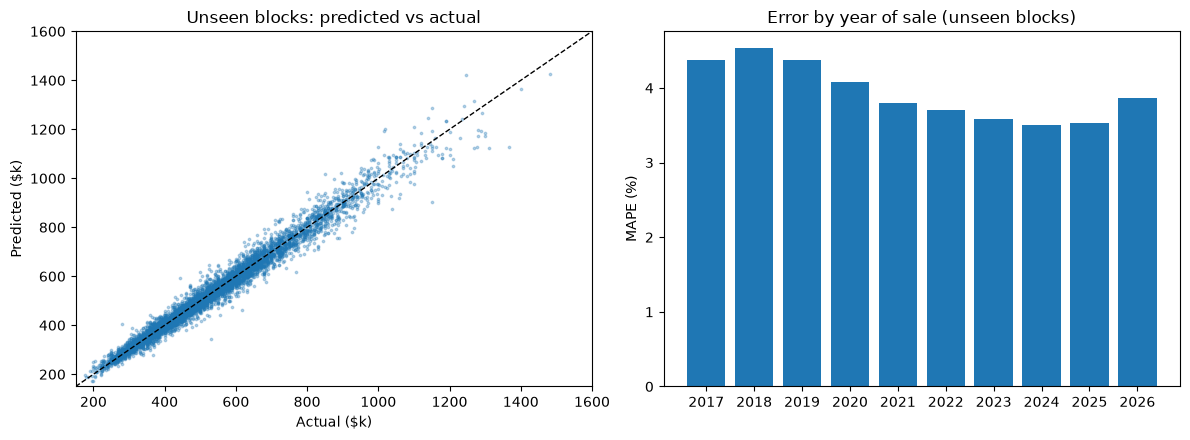

In [3]:
test["ape"] = (test["pred"] / test["resale_price"] - 1).abs()
by_type = test.groupby("flat_type")["ape"].agg(sales="size", MAPE="mean", within_10pct=lambda a: (a <= .1).mean()).loc[K.TYPES]
by_town = test.groupby("town")["ape"].agg(sales="size", MAPE="mean").sort_values("MAPE", ascending=False)
print(by_type.round(3).to_string()); print("\nHardest towns:\n" + by_town.head(6).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
s = test.sample(6000, random_state=0)
ax[0].scatter(s["resale_price"] / 1e3, s["pred"] / 1e3, s=3, alpha=.3)
lim = [150, 1600]; ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlim=lim, ylim=lim, xlabel="Actual ($k)", ylabel="Predicted ($k)",
                                                              title="Unseen blocks: predicted vs actual")
yr = test.assign(year=test["month"].str[:4]).groupby("year")["ape"].mean()
ax[1].bar(yr.index, yr.values * 100); ax[1].set(ylabel="MAPE (%)", title="Error by year of sale (unseen blocks)")
plt.tight_layout(); plt.show()

**Finding:** LightGBM prices flats in blocks it has never seen with a 3.9% average error, against 6.6% for the linear time-dummy benchmark: 94% within 10%, against 78%. R² on log price is 0.977 against 0.937. Accuracy is even across flat types (MAPE 3.7–4.3%). The hardest towns are older central estates (Geylang, Queenstown and Bukit Merah, about 5.5%), where renovation and unit condition vary most and where new premium projects sit next to 1970s blocks. Error has fallen over time, from about 4.5% (2018) to 3.5% (2024–2025), and ticks up to 3.9% in 2026 as the market moves. The model generalises: it doesn't depend on having seen a block's own sales.

## 2 · Final model: all sales up to the latest month
Number of trees chosen by early stopping on the last 6 months, then refit on everything.

In [4]:
model = H.fit(AS_OF)
train = H.training_frame(AS_OF)
print(f"{model.rounds_} trees on {len(train):,} sales up to {AS_OF}")
imp = pd.Series(model.feature_importance("gain"), index=H.FEATURES).sort_values(ascending=False)
print((imp / imp.sum()).round(3).to_string())

2598 trees on 241,273 sales up to 2026-09
t                      0.221
flat_type              0.219
floor_area_sqm         0.206
town                   0.143
remaining_lease_yrs    0.062
flat_model_group       0.051
max_floor_lvl          0.045
dist_mrt_m             0.022
storey_mid             0.014
dist_polyclinic_m      0.003
dist_hawker_m          0.003
dist_park_m            0.003
dist_primary_m         0.002
dist_supermarket_m     0.002
n_chas_500m            0.001
n_primary_1km          0.001
n_preschool_500m       0.001
n_supermarket_500m     0.001


**Finding:** By total gain, four features carry about 79% of the model:
- market timing `t` (22%)
- flat type (22%)
- floor area (21%)
- town (14%)

The next tier is remaining lease (6%), flat model (5%), block height (4.5%) and MRT distance (2%). Each amenity is under 0.3%. Gain measures how much a feature is used for splitting. SHAP below measures the size of its effect on price, and it ranks remaining lease and MRT distance higher.

## 3 · SHAP: what drives the price
SHAP values are in **log price**, so a value of 0.05 ≈ +5% on price. Computed on 5,000 sales from the last 12 months.

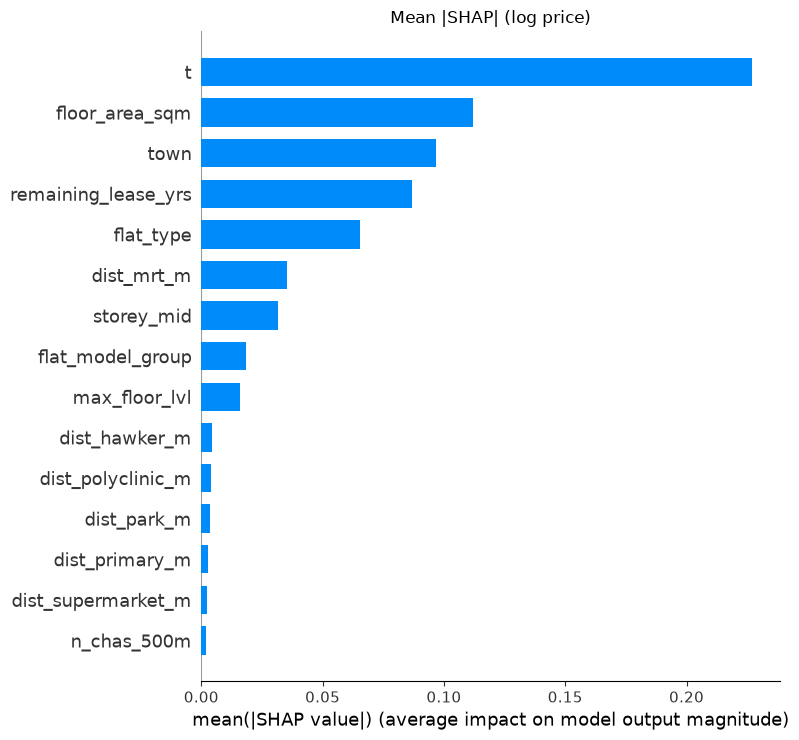

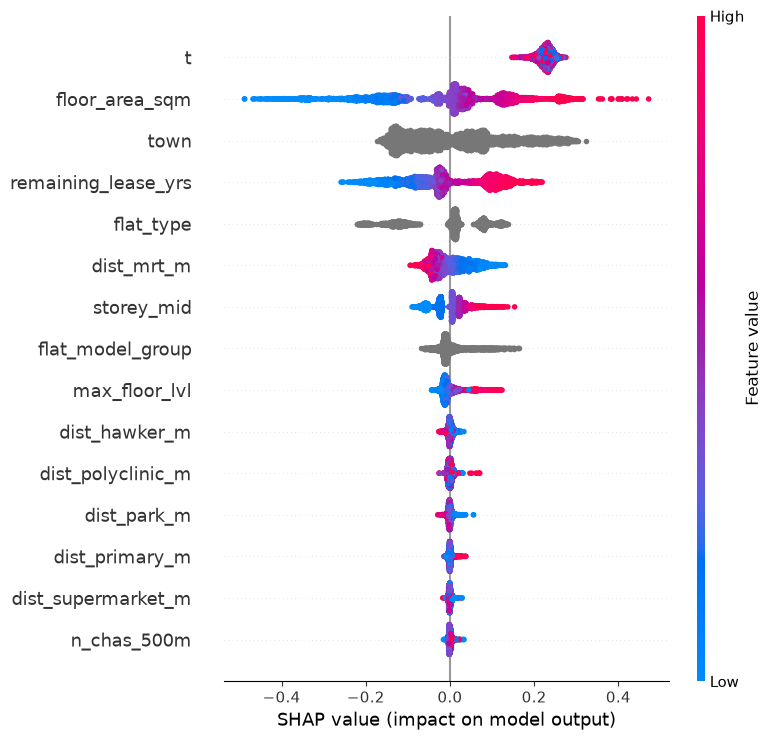

In [5]:
import shap
recent = train[train["t"] > K.month_index(AS_OF) - 12].sample(5000, random_state=1)
Xs = H._X(recent, model.categories_)
sv = shap.TreeExplainer(model).shap_values(Xs)
shap.summary_plot(sv, Xs, plot_type="bar", show=False, max_display=15); plt.title("Mean |SHAP| (log price)"); plt.tight_layout(); plt.show()
shap.summary_plot(sv, Xs, show=False, max_display=15); plt.tight_layout(); plt.show()

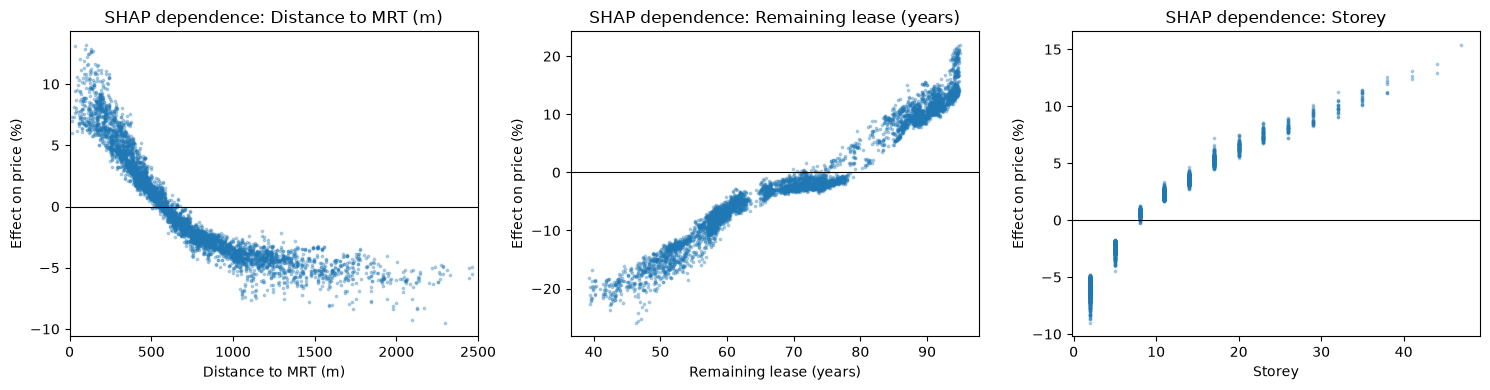

Average MRT effect by band (% vs the average flat):
500m-1km   -1.5
<500m       4.9
>1km       -4.6


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, f, xl in zip(ax, ["dist_mrt_m", "remaining_lease_yrs", "storey_mid"], ["Distance to MRT (m)", "Remaining lease (years)", "Storey"]):
    j = H.FEATURES.index(f)
    a.scatter(Xs[f], sv[:, j] * 100, s=3, alpha=.3); a.axhline(0, color="k", lw=.8)
    a.set(xlabel=xl, ylabel="Effect on price (%)", title=f"SHAP dependence: {xl}")
ax[0].set_xlim(0, 2500)
plt.tight_layout(); plt.show()

j = H.FEATURES.index("dist_mrt_m")
mb = pd.Series(K.band(recent["dist_mrt_m"], C.MRT_BANDS), index=recent.index)
eff = pd.Series(sv[:, j], index=recent.index).groupby(mb).mean()
print("Average MRT effect by band (% vs the average flat):"); print((np.expm1(eff) * 100).round(1).to_string())

**Finding:** Three main findings:
- **MRT:** +8–12% within about 200 m, zero at about 550 m, −4% at 1 km, flattening at about −5% beyond 1.2 km. The band averages are +4.9% (<500m), −1.5% (500m–1km) and −4.6% (>1km), a gap of about 10% between the nearest and furthest bands. That matches the within-town gradient in notebook 02.
- **Lease:** a plateau between 65 and 78 years (−3% to 0%). Below about 62 years it falls steeply (−10% at 57, −20% at 45), and above 80 it rises steeply (+12–20% at 90+). The 60/80 band edges sit almost exactly on these kinks.
- **Storey:** a smooth +0.5–1% per floor (−6% at floors 1–3 to +15% at 45+), with no cliff. The 21–32% raw premium for 13+ floors in notebook 01 was mostly location.

The surprise is how little amenities add once town, MRT and lease are known.

## 4 · Profile prices vs what people actually paid
`price` = units-weighted geometric mean of a representative flat in every block of the profile at the latest month.
Checked against the median price actually paid over the last 12 months, for profiles with 5+ sales.

1,828 of 1,828 profiles priced
Profiles with 5+ recent sales: 1,052 · median |diff| 2.0% · within 10%: 98% · correlation 0.993
Spread inside a profile (price_high / price_low): median 1.10


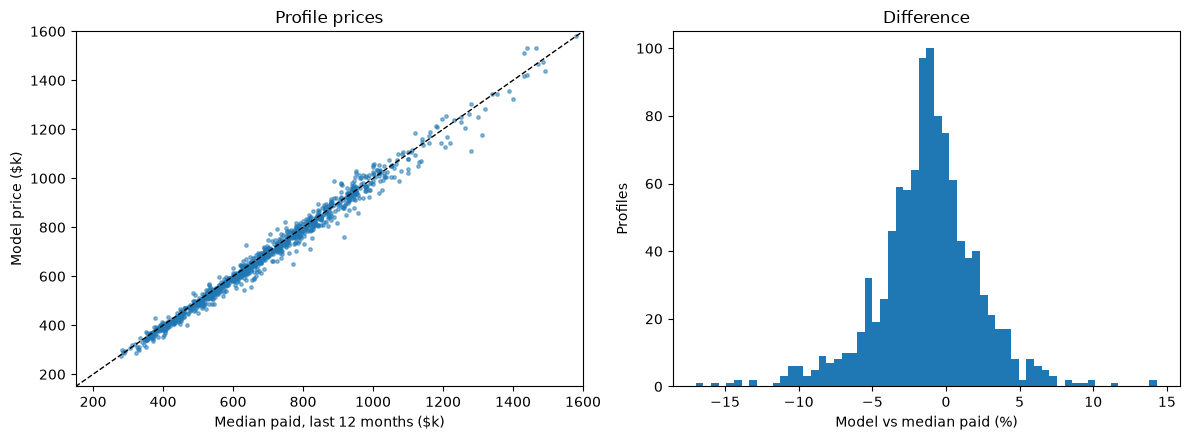

Largest gaps:
                              profile_id  n_last12  median_price_last12     price      diff
        GEYLANG|5 ROOM|<60|500m-1km|7-12         5             918000.0  762000.0 -0.169935
       CENTRAL AREA|4 ROOM|<60|<500m|1-6         7             770000.0  651000.0 -0.154545
     BUKIT MERAH|3 ROOM|<60|500m-1km|13+        10             469000.0  400000.0 -0.147122
          BISHAN|3 ROOM|<60|500m-1km|1-6         8             377000.0  431000.0  0.143236
      TOA PAYOH|4 ROOM|<60|500m-1km|7-12        12             632500.0  542000.0 -0.143083
KALLANG/WHAMPOA|4 ROOM|<60|500m-1km|7-12         9             650000.0  557000.0 -0.143077
    BUKIT PANJANG|5 ROOM|60-79|<500m|1-6         6             637944.0  726000.0  0.138031
           BEDOK|5 ROOM|80+|500m-1km|1-6         5            1280000.0 1111000.0 -0.132031


In [7]:
prices, rows = H.price_profiles(model, AS_OF)
prof = PR.current_profiles(AS_OF)
chk = prof.merge(prices, on="profile_id")
print(f"{len(prices):,} of {len(prof):,} profiles priced")
ok = chk[chk["n_last12"] >= 5].copy()
ok["diff"] = ok["price"] / ok["median_price_last12"] - 1
print(f"Profiles with 5+ recent sales: {len(ok):,} · median |diff| {ok['diff'].abs().median():.1%} · "
      f"within 10%: {(ok['diff'].abs() <= .1).mean():.0%} · correlation {np.corrcoef(ok['price'], ok['median_price_last12'])[0, 1]:.3f}")
print(f"Spread inside a profile (price_high / price_low): median {(chk['price_high'] / chk['price_low']).median():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(ok["median_price_last12"] / 1e3, ok["price"] / 1e3, s=6, alpha=.5); ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xlim=lim, ylim=lim, xlabel="Median paid, last 12 months ($k)", ylabel="Model price ($k)", title="Profile prices")
ax[1].hist(ok["diff"] * 100, bins=60); ax[1].set(xlabel="Model vs median paid (%)", ylabel="Profiles", title="Difference")
plt.tight_layout(); plt.show()
print("Largest gaps:"); print(ok.reindex(ok["diff"].abs().sort_values(ascending=False).index)
      [["profile_id", "n_last12", "median_price_last12", "price", "diff"]].head(8).to_string(index=False))

In [8]:
thin = chk[chk["n_last12"] == 0]
print(f"{len(thin):,} profiles had no sale in the last 12 months; the model still prices them from their blocks' features.")
print(thin.groupby("flat_type").size().reindex(K.TYPES).fillna(0).astype(int).to_string())

275 profiles had no sale in the last 12 months; the model still prices them from their blocks' features.
flat_type
2 ROOM        79
3 ROOM        30
4 ROOM        22
5 ROOM        33
EXECUTIVE    111


**Finding:** For the 1,052 profiles with 5+ recent sales, model prices land a median of 2.0% from what buyers actually paid over the last 12 months: 98% within 10%, correlation 0.993. The largest gaps are profiles with less than 60 years of lease in central towns (Geylang, Central Area, Bukit Merah, Toa Payoh, Kallang/Whampoa), where the model is 13–17% below a median built on only 5–12 sales. Those few sales are likely renovated or unusually well-placed units, and the model correctly doesn't chase them. 275 profiles had no recent sale (111 Executive, 79 2-room); their price comes entirely from block features. Their `price_low`–`price_high` range (median spread 1.10×) should be shown as the uncertainty.

## 5 · Backtest: priced as of Jun 2023, compared with the next 12 months
`outputs/backtest/2023-06/prices.csv` was produced by `python src/06_hedonic_prices.py 2023-06`, using only sales up to Jun 2023.
Sales from Jul 2023 to Jun 2024 are mapped to the profile their flat belonged to in Jun 2023. The benchmark is the naive
"median of the last 12 months" (what the placeholder file used).

In [9]:
BT = "2023-06"
bt = pd.read_csv(C.OUTPUTS / "backtest" / BT / "prices.csv")
key = PR.profile_rows(BT).set_index(["address", "flat_type", "storey_band"])["profile_id"]
s = K.sales(); t0 = K.month_index(BT)
nxt = s[s["in_scope"] & (s["t"] > t0) & (s["t"] <= t0 + 12)].drop(columns="profile_id")
nxt = nxt.assign(storey_band=K.band(nxt["storey_mid"], C.STOREY_BANDS)).join(key, on=["address", "flat_type", "storey_band"], how="inner")
act = nxt.groupby("profile_id")["resale_price"].agg(n="size", actual="median").query("n >= 5")
naive = PR.current_profiles(BT).set_index("profile_id")["median_price_last12"].rename("naive")
b = act.join(bt.set_index("profile_id")["price"]).join(naive).dropna()
b["model_ratio"], b["naive_ratio"] = b["actual"] / b["price"], b["actual"] / b["naive"]
summ = pd.DataFrame({m: {"median actual/predicted": b[f"{m}_ratio"].median(),
                         "10th pct": b[f"{m}_ratio"].quantile(.1), "90th pct": b[f"{m}_ratio"].quantile(.9),
                         "median |error|": (b[f"{m}_ratio"] - 1).abs().median(),
                         "error after removing market drift": (b[f"{m}_ratio"] / b[f"{m}_ratio"].median() - 1).abs().median()}
                     for m in ["model", "naive"]}).T
print(f"{len(b):,} profiles with 5+ sales in Jul 2023 – Jun 2024"); summ.round(3)

1,007 profiles with 5+ sales in Jul 2023 – Jun 2024


,median actual/predicted,10th pct,90th pct,median |error|,error after removing market drift
model,1.032,0.988,1.082,0.035,0.020
naive,1.050,1.000,1.104,0.051,0.021


**Finding:** Prices set in Jun 2023, using only data up to then, were a median of about 3% below what buyers paid over the next 12 months. The naive "median of the last 12 months" was 5.0% below. The model is the better level estimate (median error 3.5% against 5.1%) because it prices at the latest month, while a 12-month median lags about six months behind a rising market. Once the common market drift is removed, both rank profiles almost equally well (2.0% against 2.1%). The model's real value is consistency and coverage: it prices thin profiles the naive method can't. The remaining gap of about 3% a year is market growth, and adding it is the Forecasting Lead's job (`price_paths.csv`).

## 6 · Hand-over
`outputs/prices_today.csv` → `profile_id, price, price_low, price_high` (SGD, rounded to $1,000). `price_low`/`price_high`
are the 10th/90th percentile across the blocks in the profile, a range for the optimiser and the app, not a confidence interval.

In [10]:
pd.read_csv(C.OUTPUTS / "prices_today.csv").head()

,profile_id,price,price_low,price_high
0,ANG MO KIO|2 ROOM|80+|500m-1km|1-6,411000.0,411000.0,411000.0
1,ANG MO KIO|2 ROOM|80+|500m-1km|13+,455000.0,455000.0,455000.0
2,ANG MO KIO|2 ROOM|80+|500m-1km|7-12,436000.0,436000.0,436000.0
3,ANG MO KIO|2 ROOM|80+|<500m|1-6,470000.0,417000.0,504000.0
4,ANG MO KIO|2 ROOM|80+|<500m|13+,523000.0,513000.0,565000.0


**Finding:** Limitations to state in the report:
- **Unobserved unit features:** renovation, facing, view, unit position and condition aren't in the data. They are the main source of error in older central estates.
- **"Today" prices:** profile prices are as of the latest complete month (Sep 2026). Future prices come from the forecasting layer.
- **Thin profiles:** 275 profiles with no recent sales are priced from block features alone.
- **Representative flat:** `price_low`/`price_high` are the 10th/90th percentile across blocks, not a statistical confidence interval.
- **MRT at time of sale:** the model can't credit a station before it opens, even if buyers have priced it in.
- **Policy shocks:** cooling measures in the training period are absorbed by the time trend, not modelled explicitly.